<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/image_histogram_speedup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
import threading

In [1]:
from google.colab import files
yuklenen = files.upload()
dosya_adi = list(yuklenen.keys())[0]
print("Yüklenen dosya:", dosya_adi)

Saving image3.jpeg to image3.jpeg
Yüklenen dosya: image3.jpeg


Görüntü başarıyla yüklendi.
Görüntü boyutu: (270, 480)


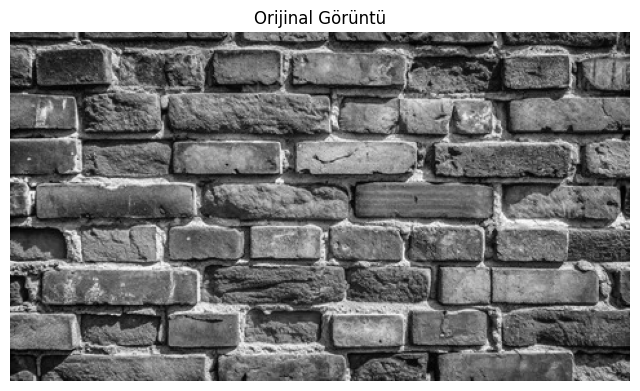

In [4]:
image = cv2.imread('/content/image3.jpeg')

if image is None:
    raise FileNotFoundError("image3.jpeg dosyası bulunamadı!")

# Görüntüyü gri tona dönüştür
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print("Görüntü başarıyla yüklendi.")
print("Görüntü boyutu:", gray_image.shape)

plt.figure(figsize=(8, 6))
plt.imshow(gray_image, cmap='gray')
plt.title("Orijinal Görüntü")
plt.axis('off')
plt.show()

In [5]:
height, width = gray_image.shape

part1 = gray_image[:height//2, :width//2]
part2 = gray_image[:height//2, width//2:]
part3 = gray_image[height//2:, :width//2]
part4 = gray_image[height//2:, width//2:]

parts = [part1, part2, part3, part4]

print("Görüntü 4 parçaya bölündü.")

for i, part in enumerate(parts):
    print(f"Parça {i+1} boyutu: {part.shape}")

Görüntü 4 parçaya bölündü.
Parça 1 boyutu: (135, 240)
Parça 2 boyutu: (135, 240)
Parça 3 boyutu: (135, 240)
Parça 4 boyutu: (135, 240)


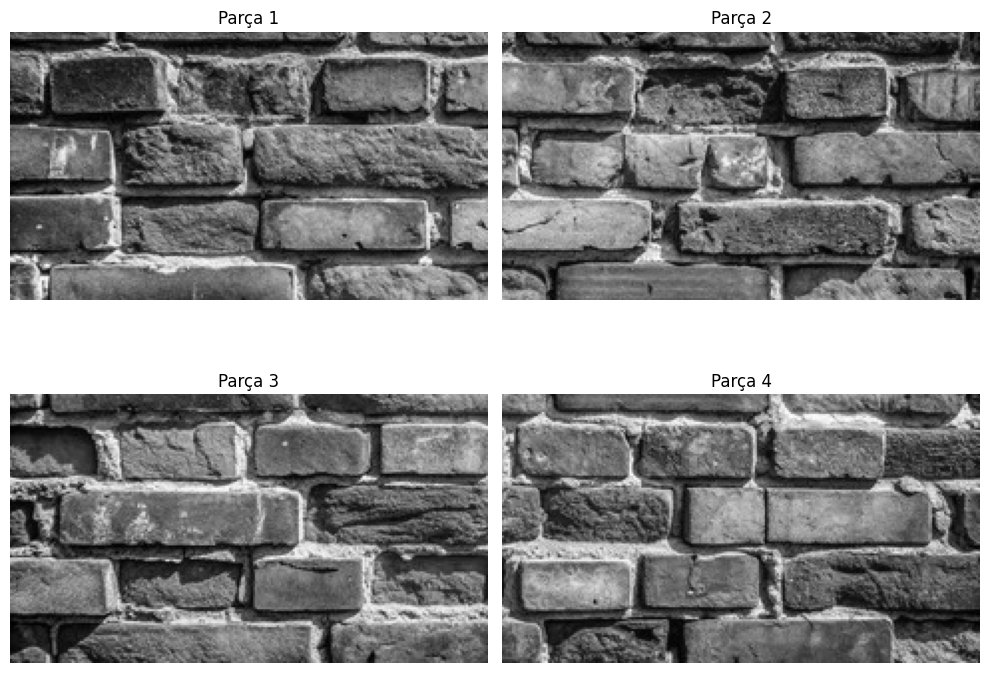

In [6]:
plt.figure(figsize=(10, 8))

for i, part in enumerate(parts):
    plt.subplot(2, 2, i+1)
    plt.imshow(part, cmap='gray')
    plt.title(f"Parça {i+1}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [7]:
def single_thread_histogram(image):

    start_time = time.perf_counter()

    histogram = cv2.calcHist(
        [image],
        [0],
        None,
        [256],
        [0, 256]
    )

    end_time = time.perf_counter()

    elapsed_time = end_time - start_time

    return histogram, elapsed_time


single_histogram, single_time = single_thread_histogram(gray_image)

print("Tek Thread Histogram Süresi:", single_time, "saniye")

Tek Thread Histogram Süresi: 0.01875042800003257 saniye


In [8]:
def four_thread_histogram(image):

    height, width = image.shape

    parts = [
        image[:height//2, :width//2],
        image[:height//2, width//2:],
        image[height//2:, :width//2],
        image[height//2:, width//2:]
    ]

    histograms = [None] * 4

    def calculate_histogram(index):
        histograms[index] = cv2.calcHist(
            [parts[index]],
            [0],
            None,
            [256],
            [0, 256]
        )

    threads = []

    start_time = time.perf_counter()

    for i in range(4):
        thread = threading.Thread(
            target=calculate_histogram,
            args=(i,)
        )

        threads.append(thread)
        thread.start()

    for thread in threads:
        thread.join()

    # Dört histogramı birleştir
    main_histogram = np.sum(histograms, axis=0)

    end_time = time.perf_counter()

    elapsed_time = end_time - start_time

    return main_histogram, elapsed_time


four_histogram, four_time = four_thread_histogram(gray_image)

print("4 Thread Histogram Süresi:", four_time, "saniye")

4 Thread Histogram Süresi: 0.004275946000007025 saniye


In [9]:
if np.array_equal(single_histogram, four_histogram):
    print("BAŞARILI: İki histogram birbirine eşittir.")
else:
    print("HATA: Histogramlar birbirinden farklı!")

BAŞARILI: İki histogram birbirine eşittir.


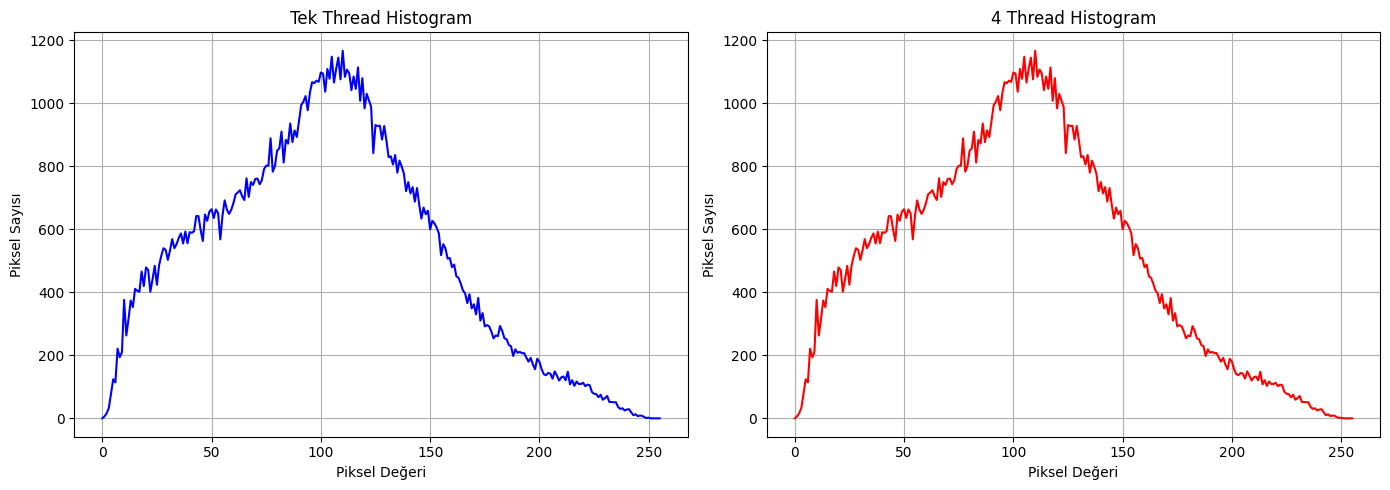

In [10]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(single_histogram, color='blue')
plt.title("Tek Thread Histogram")
plt.xlabel("Piksel Değeri")
plt.ylabel("Piksel Sayısı")
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(four_histogram, color='red')
plt.title("4 Thread Histogram")
plt.xlabel("Piksel Değeri")
plt.ylabel("Piksel Sayısı")
plt.grid()

plt.tight_layout()
plt.show()

In [11]:
print("========== SÜRE KARŞILAŞTIRMASI ==========")

print(f"Tek Thread Süresi: {single_time:.8f} saniye")
print(f"4 Thread Süresi:   {four_time:.8f} saniye")

if four_time < single_time:
    speedup = single_time / four_time
    print(f"4 Thread daha hızlı! Hızlanma: {speedup:.2f} kat")

elif single_time < four_time:
    slowdown = four_time / single_time
    print(f"Tek Thread daha hızlı! 4 Thread {slowdown:.2f} kat daha yavaş.")

else:
    print("İki yöntemin süreleri eşit.")

========== SÜRE KARŞILAŞTIRMASI ==========
Tek Thread Süresi: 0.01875043 saniye
4 Thread Süresi:   0.00427595 saniye
4 Thread daha hızlı! Hızlanma: 4.39 kat
